# Семантическая сегментация подстилающих поверхностей
## Лабораторная работа

**Цель работы:** Разработать и обучить модель машинного обучения (U-Net) для выполнения семантической сегментации (пиксельной классификации) для детектирования различных участков подстилающих поверхностей в навигационном поле мобильного робота.

**Архитектура модели:** U-Net (автоэнкодер со skip-connections)  
**Библиотека:** TensorFlow + Keras

## 1. Импорт необходимых библиотек

In [ ]:
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os
import random
import yaml

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.data import Dataset
from keras.optimizers import Adam

## 2. Параметры проекта

In [ ]:
seed = 42
num_of_channels = 3

NUM_CLASSES = 10 # 9 классов поверхностей + 1 фон (background)
BATCH_SIZE = 4
AUTOTUNE = tf.data.AUTOTUNE

HEIGHT = 256
WIDTH = 512

# Цвета из CVAT по имени класса (RGB)
label_colors_rgb = {
    "background":  (0, 0, 0),         # чёрный — фон
    "blue":        (42, 125, 209),    # #2a7dd1
    "green":       (36, 179, 83),     # #24b353
    "light_green": (221, 255, 51),    # #ddff33
    "dark_red":    (136, 49, 49),     # #883131
    "red":         (250, 50, 83),     # #fa3253
    "dark_gray":   (129, 129, 129),   # #818181
    "gray":        (189, 189, 189),   # #bdbdbd
    "white":       (255, 255, 255),   # #ffffff
    "purple":      (140, 120, 240),   # #8c78f0
}

# Для удобства: массив цветов в порядке class_id
class_names = list(label_colors_rgb.keys())
class_colors = np.array(list(label_colors_rgb.values()), dtype=np.uint8)

print("Классы сегментации:")
for i, name in enumerate(class_names):
    print(f"  {i}: {name} -> RGB{tuple(class_colors[i])}")
print(f"\nВсего классов: {NUM_CLASSES}")

Классы сегментации:
  0: background -> RGB(np.uint8(0), np.uint8(0), np.uint8(0))
  1: blue -> RGB(np.uint8(42), np.uint8(125), np.uint8(209))
  2: green -> RGB(np.uint8(36), np.uint8(179), np.uint8(83))
  3: light_green -> RGB(np.uint8(221), np.uint8(255), np.uint8(51))
  4: dark_red -> RGB(np.uint8(136), np.uint8(49), np.uint8(49))
  5: red -> RGB(np.uint8(250), np.uint8(50), np.uint8(83))
  6: dark_gray -> RGB(np.uint8(129), np.uint8(129), np.uint8(129))
  7: gray -> RGB(np.uint8(189), np.uint8(189), np.uint8(189))
  8: white -> RGB(np.uint8(255), np.uint8(255), np.uint8(255))
  9: purple -> RGB(np.uint8(140), np.uint8(120), np.uint8(240))

Всего классов: 10


## 3. Загрузка и предобработка данных

### 3.1. Предобработка масок — сопоставление пикселей с классами

In [ ]:
def rgb_mask_to_class_mask(mask_rgb, class_colors):
    """
    Преобразует RGB-маску в одноканальную маску с метками классов.
    Каждый пиксель сопоставляется с ближайшим цветом из class_colors
    по евклидову расстоянию в пространстве RGB.

    Args:
        mask_rgb: numpy array (H, W, 3), dtype=uint8
        class_colors: numpy array (NUM_CLASSES, 3), dtype=uint8

    Returns:
        class_mask: numpy array (H, W), dtype=uint8, значения [0, NUM_CLASSES-1]
    """
    h, w, _ = mask_rgb.shape
    pixels = mask_rgb.reshape(-1, 3).astype(np.float32)
    colors = class_colors.astype(np.float32)

    # Вычисляем евклидово расстояние до каждого класса
    # (N_pixels, 1, 3) - (1, N_classes, 3) -> (N_pixels, N_classes)
    dists = np.sqrt(np.sum((pixels[:, None, :] - colors[None, :, :]) ** 2, axis=2))
    class_ids = np.argmin(dists, axis=1)

    class_mask = class_ids.reshape(h, w).astype(np.uint8)
    return class_mask

# Проверка на одном изображении
sample_mask = np.array(Image.open("dataset/mask/001.png").convert("RGB"))
sample_class_mask = rgb_mask_to_class_mask(sample_mask, class_colors)

print(f"Форма исходной маски: {sample_mask.shape}")
print(f"Форма классовой маски: {sample_class_mask.shape}")
print(f"Уникальные классы в маске: {np.unique(sample_class_mask)}")
print(f"Классы: {[class_names[i] for i in np.unique(sample_class_mask)]}")

### 3.3. Функция предобработки

In [ ]:
def preprocess(image, mask):
    """
    Предобработка пары (image, mask):
    1. Нормализация изображения [0, 255] -> [0, 1]
    2. Преобразование RGB-маски в one-hot формат через ближайший цвет
    """
    # Нормализация изображения
    image = tf.cast(image, tf.float32) / 255.0

    # Преобразование маски: RGB -> class_id -> one-hot
    # Используем tf.py_function для numpy-операции
    def _mask_to_onehot(mask_tensor):
        mask_np = mask_tensor.numpy().astype(np.uint8)
        batch_size = mask_np.shape[0]
        result = np.zeros((batch_size, HEIGHT, WIDTH, NUM_CLASSES), dtype=np.float32)

        for i in range(batch_size):
            class_mask = rgb_mask_to_class_mask(mask_np[i], class_colors)
            result[i] = np.eye(NUM_CLASSES, dtype=np.float32)[class_mask]

        return result

    mask_onehot = tf.py_function(
        _mask_to_onehot,
        [mask],
        tf.float32
    )
    mask_onehot.set_shape([None, HEIGHT, WIDTH, NUM_CLASSES])

    return image, mask_onehot

# Применяем предобработку ко всему датасету
data_ds = data_tf.map(preprocess, num_parallel_calls=AUTOTUNE)
print("Предобработка применена.")

Предобработка применена.


### 3.4. Разделение на обучающую, валидационную и тестовую выборки

In [ ]:
TRAIN_LENGTH = int(0.6 * len(data_ds))
VAL_LENGTH = int(0.2 * len(data_ds))
TEST_LENGTH = len(data_ds) - TRAIN_LENGTH - VAL_LENGTH

# Разделение
train_ds = data_ds.take(TRAIN_LENGTH)
val_ds = data_ds.skip(TRAIN_LENGTH).take(VAL_LENGTH)
test_ds = data_ds.skip(TRAIN_LENGTH).skip(VAL_LENGTH)

# Перемешивание обучающей выборки и оптимизация
train_ds = train_ds.shuffle(buffer_size=len(data_ds), seed=seed).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print(f"train | batches: {len(train_ds)} | images: {len(train_ds) * BATCH_SIZE}")
print(f"val   | batches: {len(val_ds)} | images: {len(val_ds) * BATCH_SIZE}")
print(f"test  | batches: {len(test_ds)} | images: {len(test_ds) * BATCH_SIZE}")

train | batches: 19 | images: 76
val   | batches: 6 | images: 24
test  | batches: 7 | images: 28


### 3.5. Отладка данных

In [ ]:
def debug_dataset(dataset, name="Dataset"):
    """Отладка датасета перед обучением"""
    print(f"\n=== {name} Debug ===")
    for images, masks in dataset.take(1):
        print(f"Shape: Images {images.shape}, Masks {masks.shape}")
        print(f"Dtype: Images {images.dtype}, Masks {masks.dtype}")
        print(f"Range: Images [{tf.reduce_min(images):.3f}, {tf.reduce_max(images):.3f}]")
        print(f"Range: Masks [{tf.reduce_min(masks):.3f}, {tf.reduce_max(masks):.3f}]")

        if tf.reduce_any(tf.math.is_nan(images)):
            print("WARNING: Images contain NaN!")
        if tf.reduce_any(tf.math.is_nan(masks)):
            print("WARNING: Masks contain NaN!")
        break

debug_dataset(train_ds, "Training Data")
debug_dataset(val_ds, "Validation Data")
debug_dataset(test_ds, "Test Data")


=== Training Data Debug ===
Shape: Images (4, 256, 512, 3), Masks (4, 256, 512, 10)
Dtype: Images <dtype: 'float32'>, Masks <dtype: 'float32'>
Range: Images [0.000, 1.000]
Range: Masks [0.000, 1.000]

=== Validation Data Debug ===
Shape: Images (4, 256, 512, 3), Masks (4, 256, 512, 10)
Dtype: Images <dtype: 'float32'>, Masks <dtype: 'float32'>
Range: Images [0.000, 1.000]
Range: Masks [0.000, 1.000]

=== Test Data Debug ===
Shape: Images (4, 256, 512, 3), Masks (4, 256, 512, 10)
Dtype: Images <dtype: 'float32'>, Masks <dtype: 'float32'>
Range: Images [0.000, 1.000]
Range: Masks [0.000, 1.000]


### 3.6. Визуализация обучающей выборки

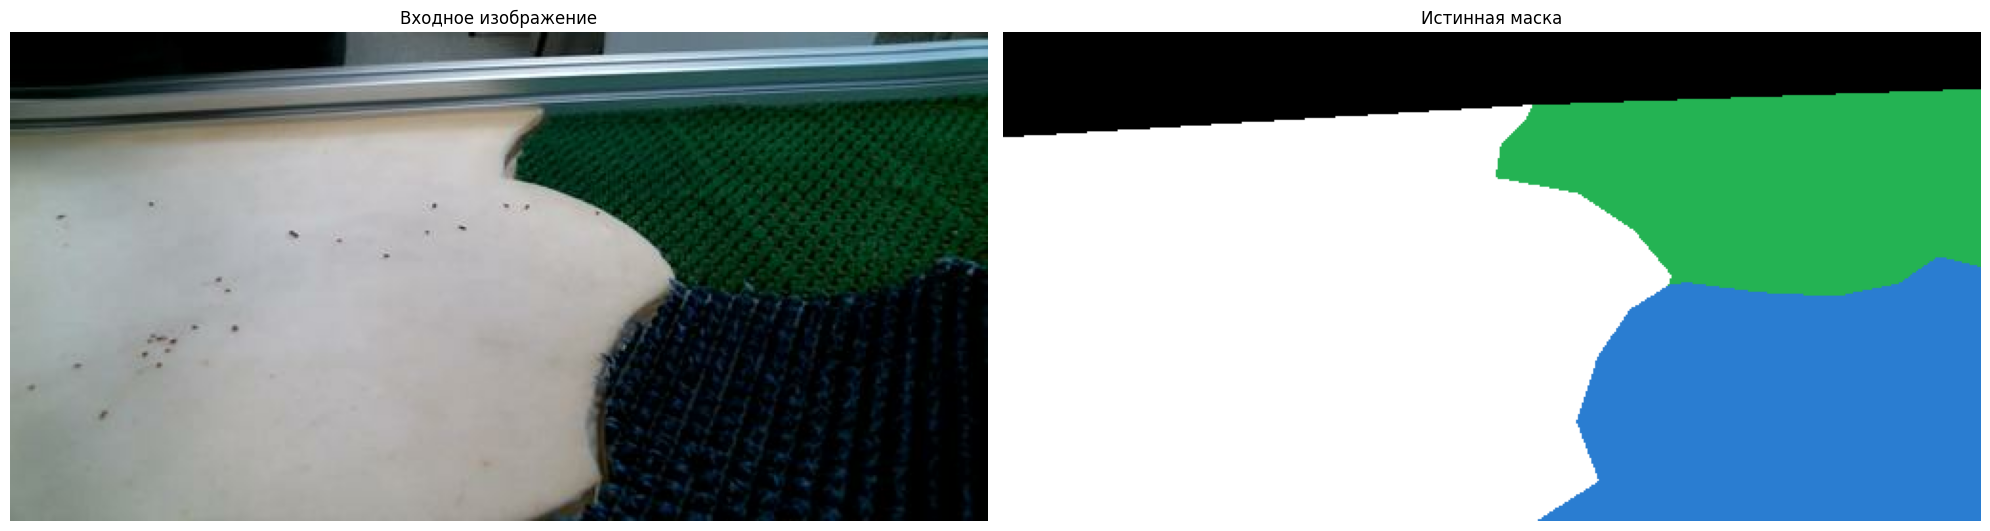

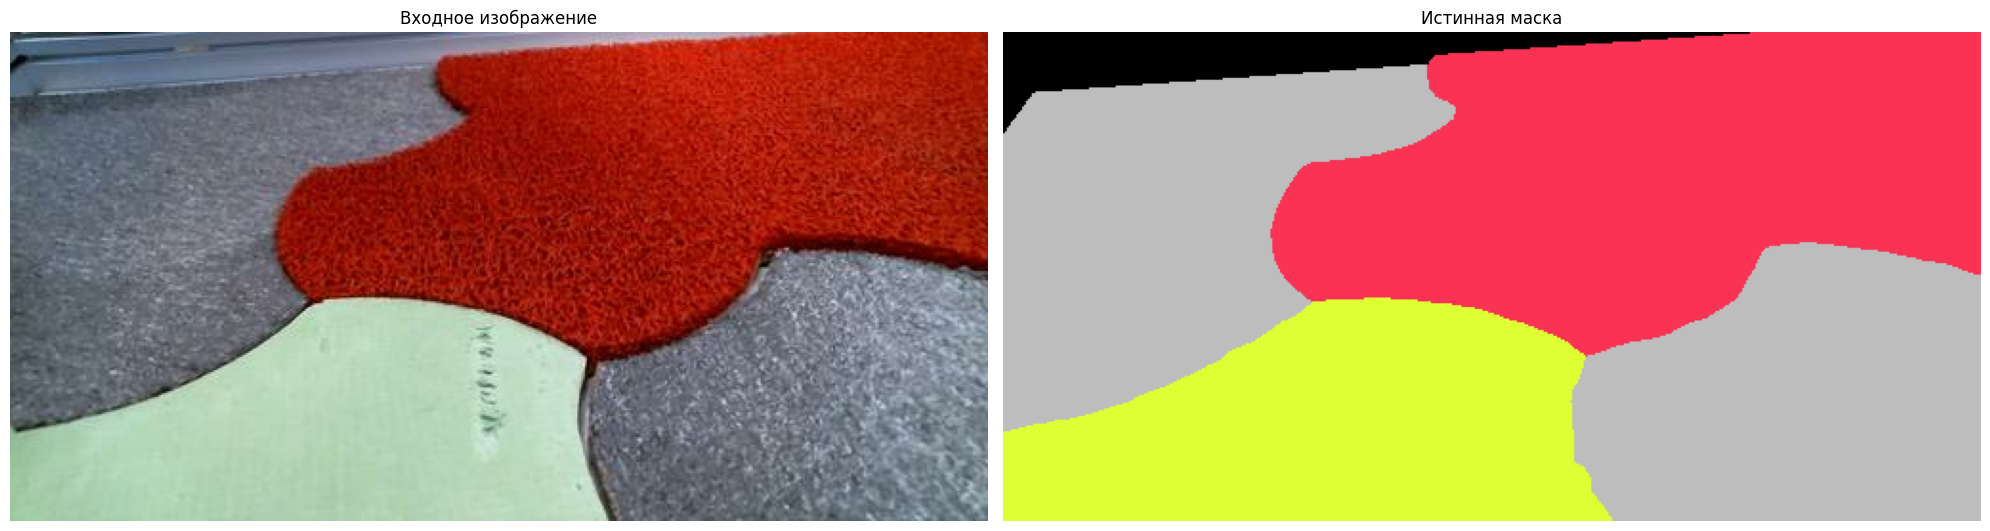

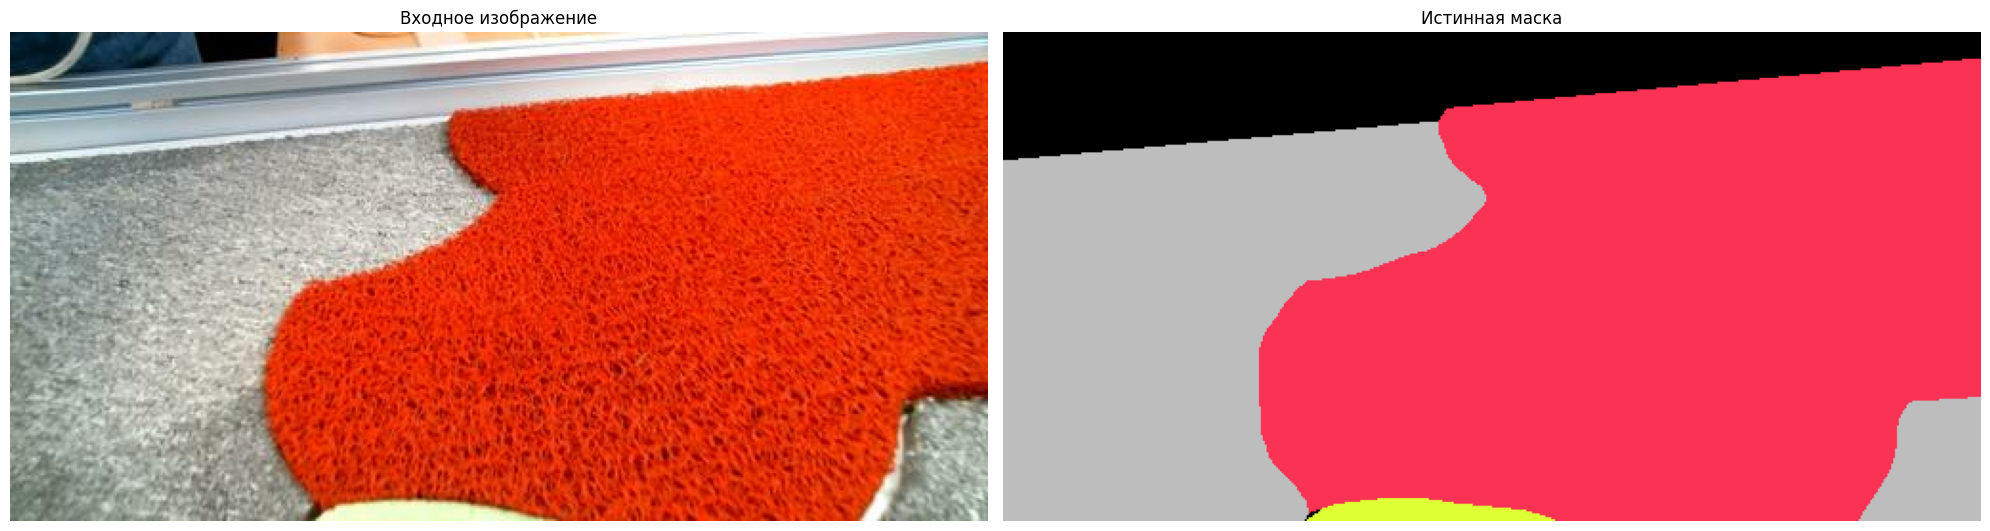

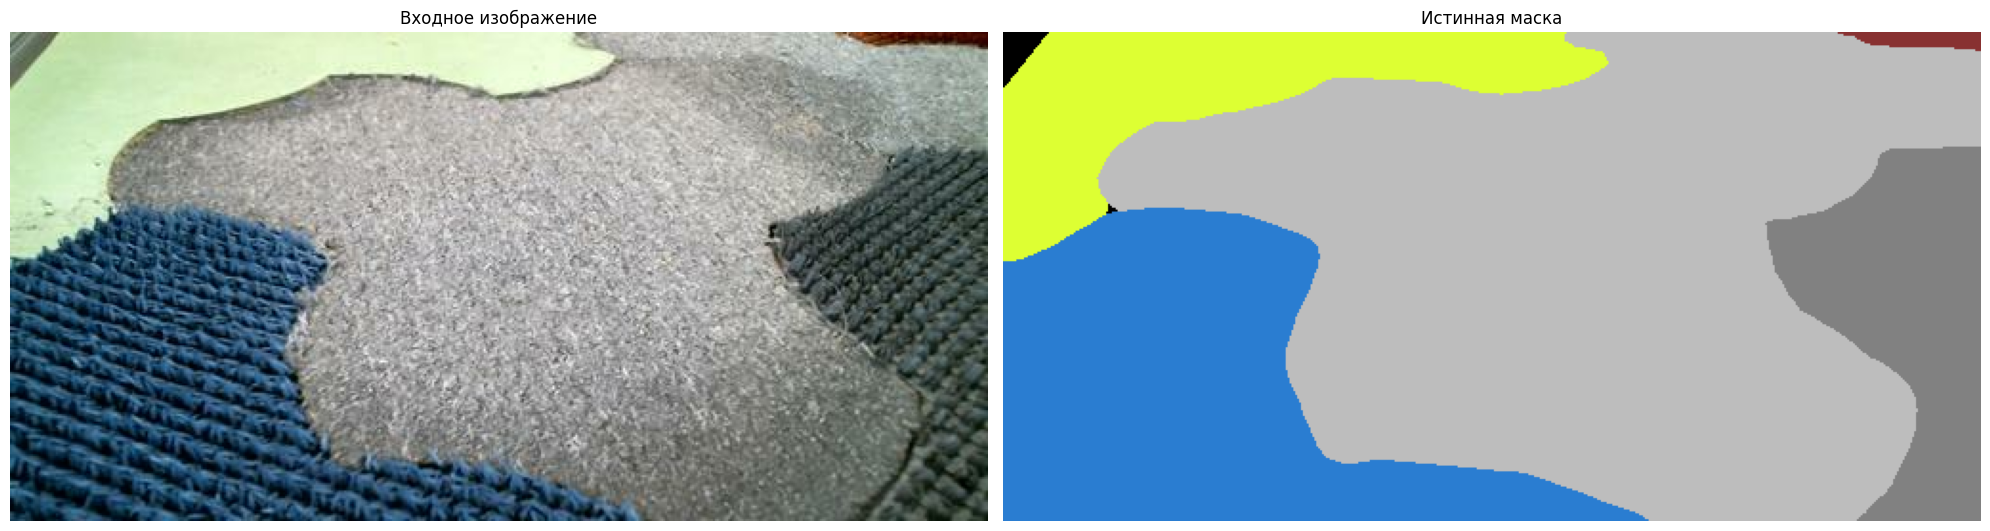

In [ ]:
def show_images(display_list, class_colors=None, class_names=None):
    plt.figure(figsize=(20, 6))
    title = ['Входное изображение', 'Истинная маска', 'Предсказанная маска']

    for i in range(len(display_list)):
        plt.subplot(1, len(display_list), i + 1)
        plt.title(title[i])

        if i == 0:
            # Исходное изображение
            plt.imshow(display_list[i].numpy())
        else:
            # Маска — конвертируем argmax обратно в цветное изображение
            if len(display_list[i].shape) == 3 and display_list[i].shape[-1] == NUM_CLASSES:
                mask_ids = np.argmax(display_list[i].numpy(), axis=-1)
            else:
                mask_ids = display_list[i] if isinstance(display_list[i], np.ndarray) else display_list[i].numpy()

            # Создаём цветную маску
            h, w = mask_ids.shape
            color_mask = np.zeros((h, w, 3), dtype=np.uint8)
            for cls_id in range(len(class_colors)):
                color_mask[mask_ids == cls_id] = class_colors[cls_id]
            plt.imshow(color_mask)

        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Визуализация нескольких примеров
imgs, masks = next(iter(train_ds.take(1)))
for i in range(min(4, imgs.shape[0])):
    show_images([imgs[i], masks[i]], class_colors, class_names)

## 4. Создание модели U-Net

### 4.1. Архитектура

U-Net — это архитектура типа автоэнкодер с **skip-connections** (пропущенными соединениями),
которые передают карты признаков из энкодера непосредственно в декодер.
Это позволяет сохранить пространственную информацию (текстуры, границы),
которая теряется при пулинге.

**Обоснование выбора:**
- U-Net специально разработана для задачи семантической сегментации
- Skip-connections решают проблему потери пространственных деталей в базовом автоэнкодере
- Хорошо работает даже на небольших наборах данных
- Используется конкатенация признаков (как в DenseNet), а не сложение (как в ResNet)

In [ ]:
def build_unet(input_shape, num_classes):
    """
    U-Net с skip-connections (DenseNet-style concatenation).

    Энкодер: Conv -> Conv -> MaxPool (3 уровня)
    Bottleneck: Conv -> Conv
    Декодер: Conv2DTranspose -> Concatenate -> Conv -> Conv (3 уровня)
    """
    inputs = tf.keras.Input(shape=input_shape)

    # --------------->> Энкодер <<---------------

    # Блок 1
    c1 = tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    c1 = tf.keras.layers.BatchNormalization()(c1)
    c1 = tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same')(c1)
    c1 = tf.keras.layers.BatchNormalization()(c1)
    p1 = tf.keras.layers.MaxPooling2D(2)(c1)  # (256, 512) -> (128, 256)

    # Блок 2
    c2 = tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same')(p1)
    c2 = tf.keras.layers.BatchNormalization()(c2)
    c2 = tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same')(c2)
    c2 = tf.keras.layers.BatchNormalization()(c2)
    p2 = tf.keras.layers.MaxPooling2D(2)(c2)  # (128, 256) -> (64, 128)

    # Блок 3
    c3 = tf.keras.layers.Conv2D(128, 3, activation='relu', padding='same')(p2)
    c3 = tf.keras.layers.BatchNormalization()(c3)
    c3 = tf.keras.layers.Conv2D(128, 3, activation='relu', padding='same')(c3)
    c3 = tf.keras.layers.BatchNormalization()(c3)
    p3 = tf.keras.layers.MaxPooling2D(2)(c3)  # (64, 128) -> (32, 64)

    # ----> Латентное пространство (Bottleneck) <<----

    b = tf.keras.layers.Conv2D(256, 3, activation='relu', padding='same')(p3)
    b = tf.keras.layers.BatchNormalization()(b)
    b = tf.keras.layers.Conv2D(256, 3, activation='relu', padding='same')(b)
    b = tf.keras.layers.BatchNormalization()(b)

    # --------------->> Декодер <<---------------

    # Блок 4 (skip-connection от c3)
    u4 = tf.keras.layers.Conv2DTranspose(128, 3, strides=2, padding='same')(b)
    u4 = tf.keras.layers.concatenate([u4, c3])  # Skip-connection
    c4 = tf.keras.layers.Conv2D(128, 3, activation='relu', padding='same')(u4)
    c4 = tf.keras.layers.BatchNormalization()(c4)
    c4 = tf.keras.layers.Conv2D(128, 3, activation='relu', padding='same')(c4)
    c4 = tf.keras.layers.BatchNormalization()(c4)

    # Блок 5 (skip-connection от c2)
    u5 = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding='same')(c4)
    u5 = tf.keras.layers.concatenate([u5, c2])  # Skip-connection
    c5 = tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same')(u5)
    c5 = tf.keras.layers.BatchNormalization()(c5)
    c5 = tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same')(c5)
    c5 = tf.keras.layers.BatchNormalization()(c5)

    # Блок 6 (skip-connection от c1)
    u6 = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding='same')(c5)
    u6 = tf.keras.layers.concatenate([u6, c1])  # Skip-connection
    c6 = tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same')(u6)
    c6 = tf.keras.layers.BatchNormalization()(c6)
    c6 = tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same')(c6)
    c6 = tf.keras.layers.BatchNormalization()(c6)

    # ------------->> Выходной слой <<-------------
    outputs = tf.keras.layers.Conv2D(num_classes, 1, activation='softmax')(c6)

    model = tf.keras.Model(inputs, outputs, name="UNet")
    return model

model = build_unet((HEIGHT, WIDTH, num_of_channels), NUM_CLASSES)
model.summary()

Model: "UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 512,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 512,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 512,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 512,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 256,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 256,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 256,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 256,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 256,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 128,   │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 128,   │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128,   │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 128,   │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 128,   │        512 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 64,    │    295,168 │ max_pooling2d_2[

 Total params: 2,146,570 (8.19 MB)

 Trainable params: 2,143,754 (8.18 MB)

 Non-trainable params: 2,816 (11.00 KB)

### 4.2. Компиляция модели

**Обоснование выбора:**
- **Оптимизатор Adam:** адаптивный learning rate, хорошо работает по умолчанию
- **Learning rate 1e-4:** консервативный, предотвращает нестабильность обучения
- **categorical_crossentropy:** стандартная функция потерь для многоклассовой пиксельной классификации (one-hot формат)
- **OneHotIoU:** основная метрика для сегментации — Intersection over Union,
  исключая фоновый класс (id=0) из расчёта, чтобы не завышать метрику

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=[
        keras.metrics.OneHotIoU(
            num_classes=NUM_CLASSES,
            name="OHIoU",
            target_class_ids=list(range(1, NUM_CLASSES)),  # исключаем фон (0)
            sparse_y_pred=False
        ),
        'accuracy'
    ],
)

print("Модель скомпилирована.")

Модель скомпилирована.


## 5. Обучение модели

### 5.1. Настройка чекпоинтов

Чекпоинт сохраняет лучшую версию модели по метрике `val_OHIoU` (IoU на валидации).
Это необходимо для отслеживания момента переобучения - когда точность на обучающей выборке
растёт, а на валидационной начинает падать.

In [17]:
# Путь для сохранения чекпоинтов
checkpoint_dir = "models/segmentation/"
checkpoint_path = os.path.join(checkpoint_dir, "model_loss-{val_loss:.3f}_OHIoU-{val_OHIoU:.3f}.keras")

os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_OHIoU',
    save_best_only=True,
    verbose=1,
    save_freq='epoch',
    mode='max',
)

print(f'Checkpoint save to {checkpoint_path}')

Checkpoint save to models/segmentation/model_loss-{val_loss:.3f}_OHIoU-{val_OHIoU:.3f}.keras


### 5.2. Запуск обучения

In [18]:
EPOCHS = 50

print(f"EPOCHS: {EPOCHS}")
print(f"BATCH_SIZE: {BATCH_SIZE}")
print(f"Обучающих батчей: {len(train_ds)}")
print(f"Валидационных батчей: {len(val_ds)}")
print()

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=[checkpoint_callback],
)

print(f'Model Trained!')

EPOCHS: 50
BATCH_SIZE: 4
Обучающих батчей: 19
Валидационных батчей: 6

Epoch 1/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - OHIoU: 0.0772 - accuracy: 0.1549 - loss: 2.7759
Epoch 1: val_OHIoU improved from None to 0.02785, saving model to models/segmentation/model_loss-2.281_OHIoU-0.028.keras

Epoch 1: finished saving model to models/segmentation/model_loss-2.281_OHIoU-0.028.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 57s 869ms/step - OHIoU: 0.1184 - accuracy: 0.2262 - loss: 2.4708 - val_OHIoU: 0.0279 - val_accuracy: 0.2086 - val_loss: 2.2807
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - OHIoU: 0.2674 - accuracy: 0.4519 - loss: 1.7021
Epoch 2: val_OHIoU did not improve from 0.02785
19/19 ━━━━━━━━━━━━━━━━━━━━ 14s 521ms/step - OHIoU: 0.3063 - accuracy: 0.4999 - loss: 1.5864 - val_OHIoU: 0.0230 - val_accuracy: 0.1620 - val_loss: 2.2821
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - OHIoU: 0.4333 - accuracy: 0.6371 - loss: 1.2399
Epoch 3: val_OHIoU improved from 0.02785 to 0.03428, sav

### 5.3. Сохранение модели

In [19]:
model.save(checkpoint_dir + "trained_model.keras")
print(f'Model Saved!')

Model Saved!


## 6. Анализ результатов обучения

### 6.1. Графики обучения

Графики позволяют визуально оценить наличие переобучения:
- Если `val_loss` начинает расти при падении `loss` — модель переобучается
- Лучшая эпоха — та, где `val_OHIoU` максимален

Параметры: ['OHIoU', 'accuracy', 'loss', 'val_OHIoU', 'val_accuracy', 'val_loss']


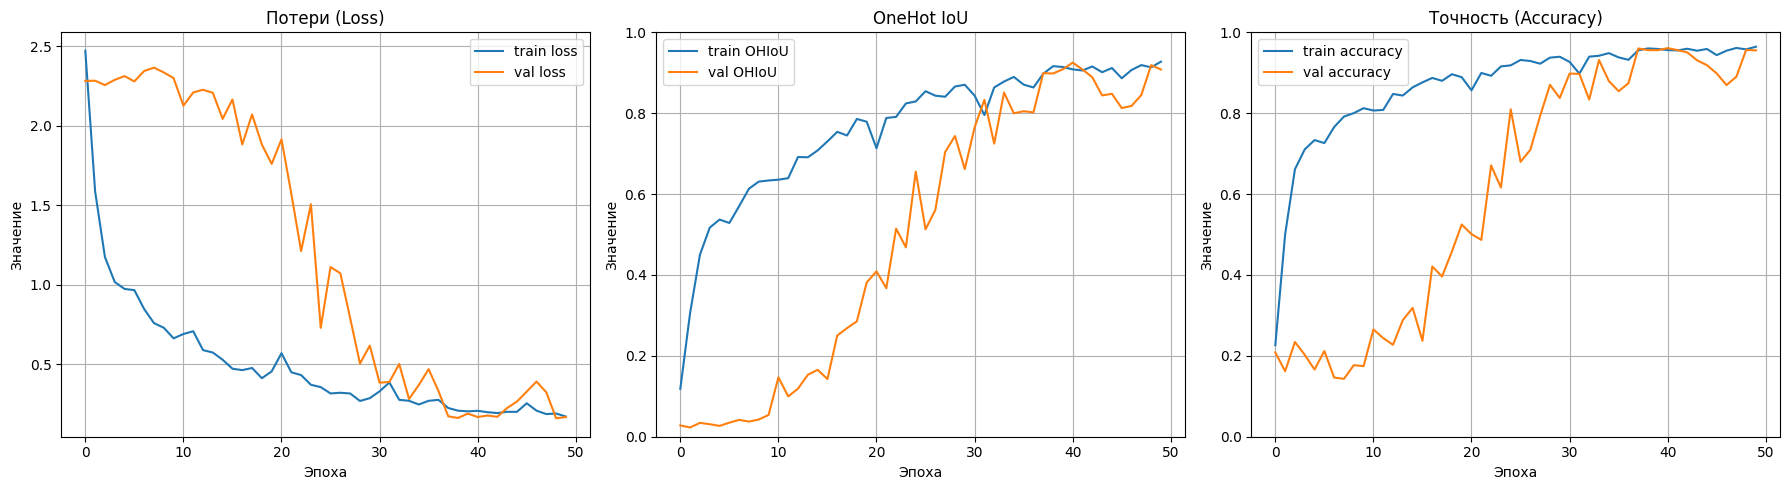

In [20]:
params = list(history.history.keys())
print("Параметры:", params)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(history.history['loss'], label='train loss')
axes[0].plot(history.history['val_loss'], label='val loss')
axes[0].set_title('Потери (Loss)')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Значение')
axes[0].legend()
axes[0].grid(True)

# OHIoU
axes[1].plot(history.history['OHIoU'], label='train OHIoU')
axes[1].plot(history.history['val_OHIoU'], label='val OHIoU')
axes[1].set_title('OneHot IoU')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Значение')
axes[1].legend()
axes[1].grid(True)
axes[1].set_ylim(0, 1)

# Accuracy
axes[2].plot(history.history['accuracy'], label='train accuracy')
axes[2].plot(history.history['val_accuracy'], label='val accuracy')
axes[2].set_title('Точность (Accuracy)')
axes[2].set_xlabel('Эпоха')
axes[2].set_ylabel('Значение')
axes[2].legend()
axes[2].grid(True)
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.savefig('models/segmentation/model_history.png', dpi=150)
plt.show()

## 7. Тестирование модели

### 7.1. Метрики на тестовой выборке

In [21]:
results = model.evaluate(test_ds, return_dict=True)
print("\nРезультаты на тестовой выборке:")
for key, value in results.items():
    print(f"  {key}: {value:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - OHIoU: 0.9110 - accuracy: 0.9507 - loss: 0.1661

Результаты на тестовой выборке:
  OHIoU: 0.9110
  accuracy: 0.9507
  loss: 0.1661


### 7.2. Визуализация предсказаний

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


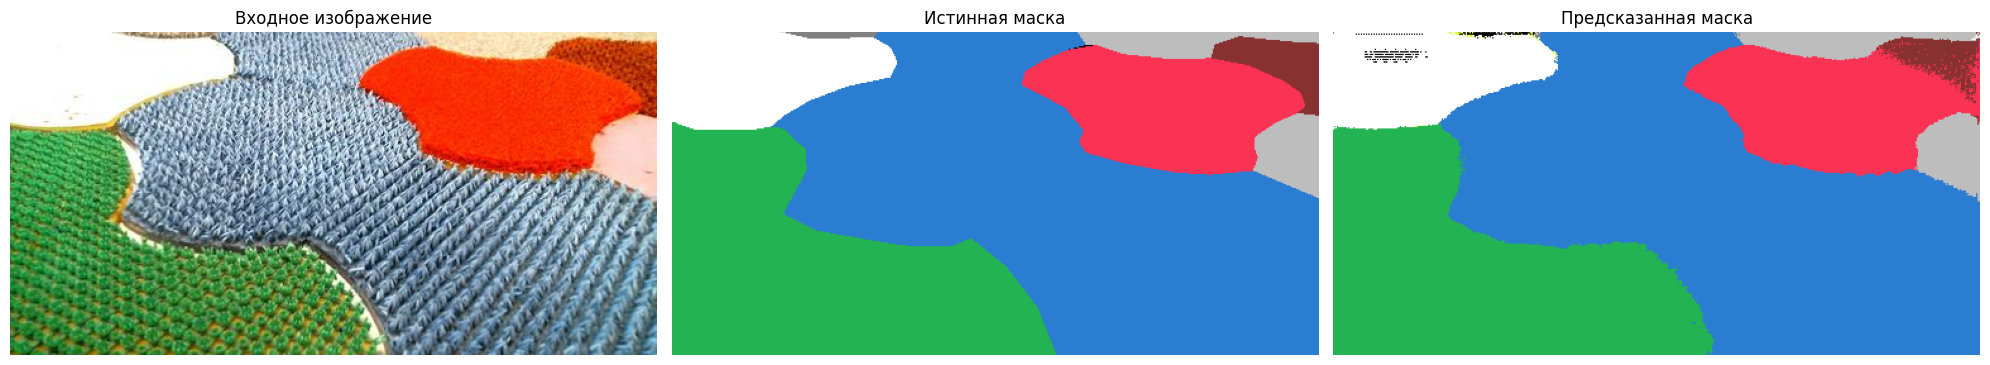

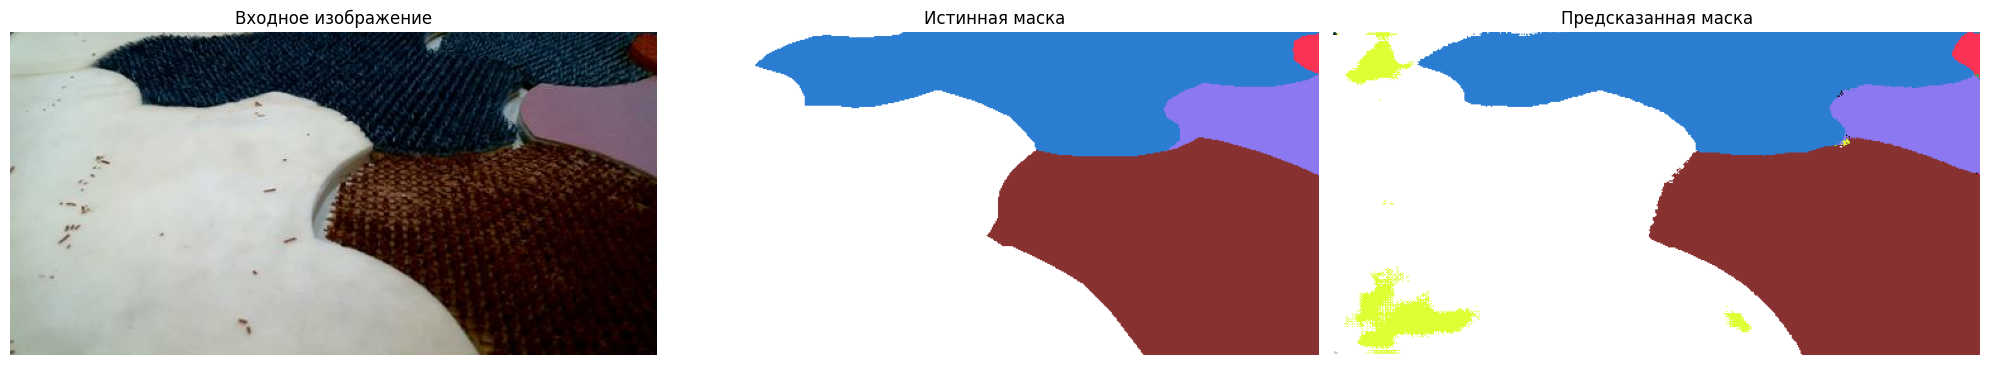

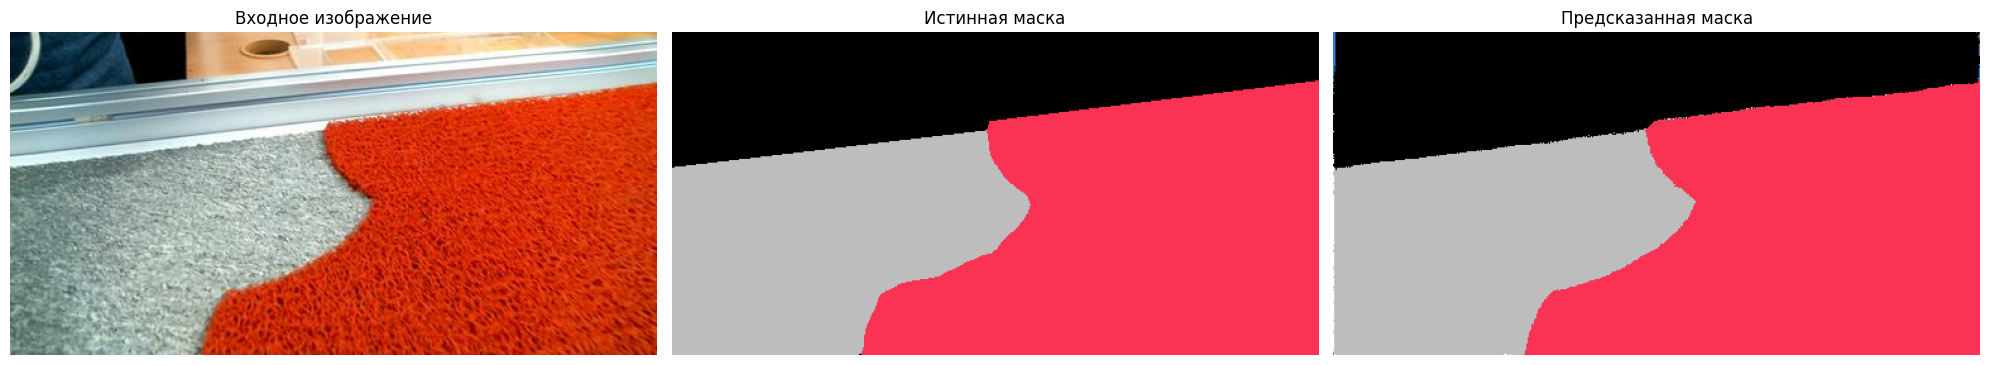

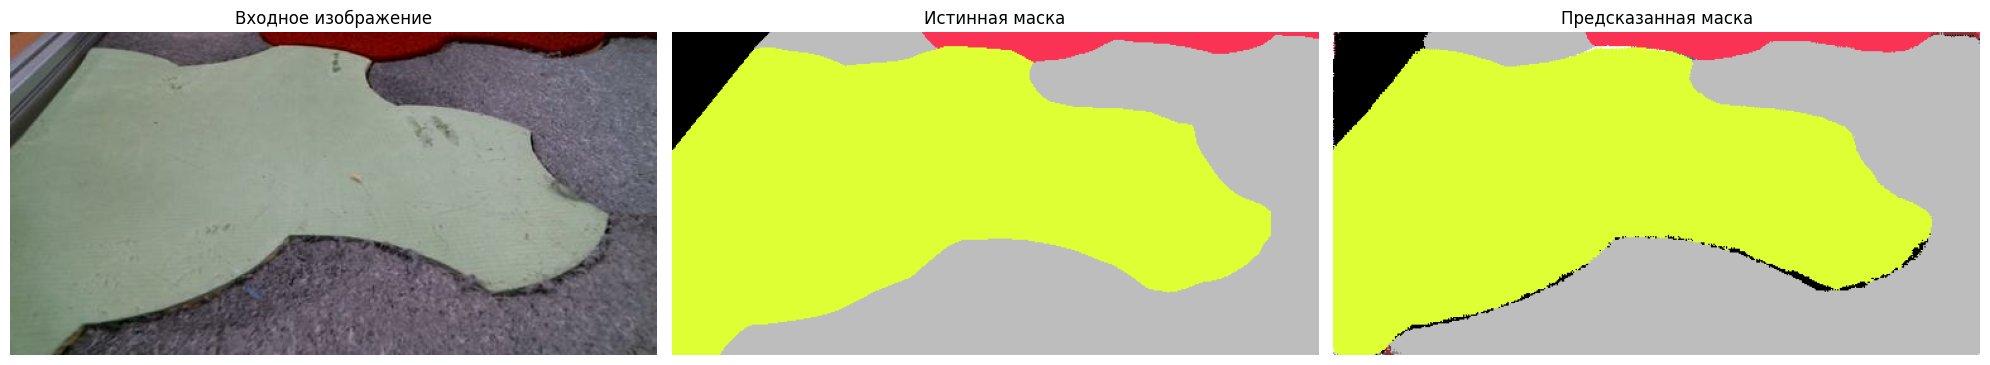

In [22]:
X_test_batch, Y_test_batch = next(iter(test_ds.take(1)))
out = model.predict(X_test_batch)
pred = np.argmax(out, axis=3)

for i in range(min(BATCH_SIZE, X_test_batch.shape[0])):
    show_images([X_test_batch[i], Y_test_batch[i], pred[i]], class_colors, class_names)

## 8. Выводы

### Обоснование принятых решений:

1. **Архитектура U-Net:** Выбрана как наиболее подходящая для семантической сегментации.
   Базовый автоэнкодер теряет пространственную информацию при пулинге.
   Skip-connections в U-Net решают эту проблему, передавая детальные карты признаков из энкодера в декодер.

2. **Конкатенация (DenseNet-style):** Используется вместо сложения (ResNet-style),
   что позволяет декодеру использовать как высокоуровневые семантические,
   так и низкоуровневые пространственные признаки.

3. **BatchNormalization:** Добавлен для стабилизации обучения и ускорения сходимости.

4. **Предобработка масок (nearest-color matching):** Необходима, т.к. при экспорте из CVAT
   маски сжимаются и края между классами размываются — количество уникальных цветов
   становится больше числа классов.

5. **categorical_crossentropy + OneHotIoU:** Стандартная комбинация для задач
   многоклассовой пиксельной классификации. IoU — более информативная метрика,
   чем accuracy, т.к. учитывает совпадение областей, а не отдельных пикселей.

6. **Исключение фона из метрики IoU:** Фоновый класс обычно занимает большую часть изображения,
   что может искусственно завышать метрику.

## Загрузка моделей на компьютер

In [ ]:
# !zip -r models.zip models/
# from google.colab import files
# files.download('models.zip')